In [10]:
import sys
sys.path.append("..")

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from clean_data import feature_engineering

In [11]:
df= pd.read_csv("../data/austin/raw/aac_intakes_outcomes.csv")

In [12]:
df["days_in_shelters"] = pd.to_timedelta(df["time_in_shelter"]).dt.days
df["is_mixed_breed"] = df["breed"].str.contains("/|Mix", na=False).astype(int)
df["primary_breed"] = df["breed"].str.split("/|Mix").str[0].str.strip()

# Feature Engineering & EDA

This notebook focuses on exploring engineered features and their relationships with shelter outcomes to identify relevant predictors and support further ML/DL model development.

In [13]:
df = feature_engineering(df)

In [14]:
df["outcome_type"].value_counts(normalize=True)*100

# The distribution of outcome types is imbalanced, with some
# categories occurring significantly more frequently than others.
# This should be considered during model training and evaluation,
# particularly when selecting metrics such as Macro F1-score.

outcome_type
Adoption           46.449549
Transfer           29.039241
Return to Owner    20.268593
Death               4.242616
Name: proportion, dtype: float64

<Axes: xlabel='outcome_type'>

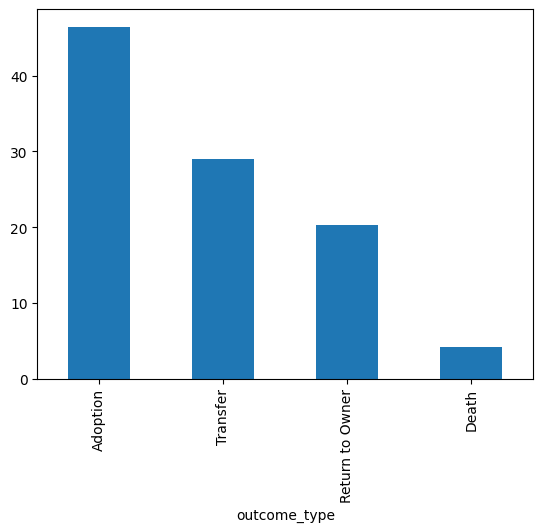

In [15]:
df["outcome_type"].value_counts(normalize=True).mul(100).plot(kind="bar")

In [16]:
df["intake_type"].value_counts(normalize=True)*100

#strays predominate – the shelter primarily takes in animals without owners
#intake_type can influence the outcome

intake_type
Stray              72.837821
Owner Surrender    20.485034
Public Assist       6.677145
Name: proportion, dtype: float64

In [17]:
df["intake_condition"].value_counts(normalize=True)*100
#most animals have intake_condition = 'normal'
#an animal's condition influences the outcome and can be an important feature in the model which can differ transfer from adoption
#it can mean that the well-kept animals have bigger chance for adoption??

intake_condition
Normal     90.198674
Injured     4.359515
Sick        2.673340
Nursing     2.017069
Other       0.751403
Name: proportion, dtype: float64

<Axes: xlabel='outcome_type', ylabel='age_group'>

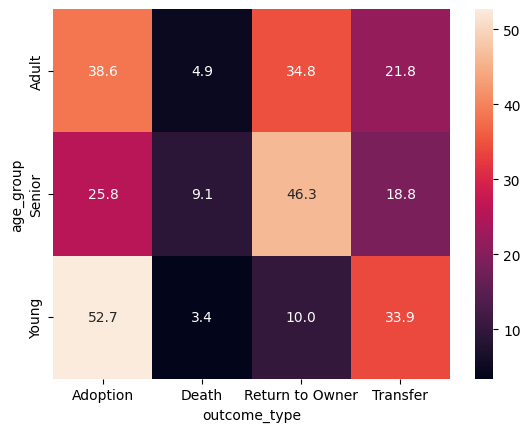

In [18]:
age_outcome = pd.crosstab(df["age_group"], df["outcome_type"], normalize="index").mul(100).round(2)

sns.heatmap(
    age_outcome,
    annot=True,
    fmt=".1f",
)

# Outcome distributions vary across age groups, suggesting
# that age may be a relevant feature for outcome prediction.
# However, these relationships should not be interpreted
# as causal effects.

<Axes: xlabel='outcome_type', ylabel='days_in_shelters'>

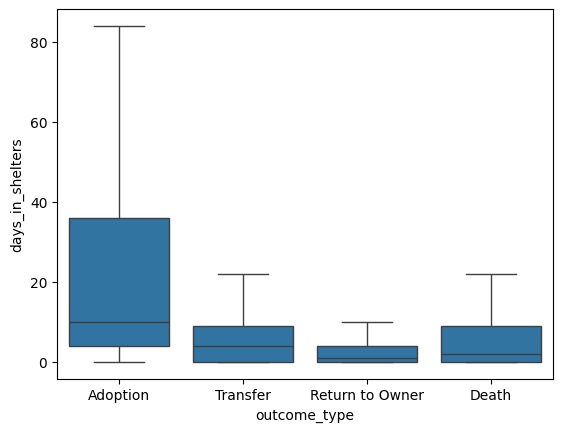

In [19]:
sns.boxplot(data=df, x="outcome_type", y = "days_in_shelters",
            order=["Adoption","Transfer","Return to Owner","Death"],
            showfliers=False)

# Length of stay varies across outcome types, suggesting
# that shelter duration may be an interesting prediction target.
# Possible approaches include regression to estimate the number
# of days or classification of long-stay risk.

# Actual length of stay should not be used as an input feature
# when predicting outcomes at the time of intake, as this
# would introduce data leakage, but we can deliver outcome from the first model
# which predict length of stay 

In [20]:
outcome_ohe = pd.get_dummies(df["outcome_type"], prefix="outcome")
num_cols = df.select_dtypes(include=["number"]).columns

<Axes: >

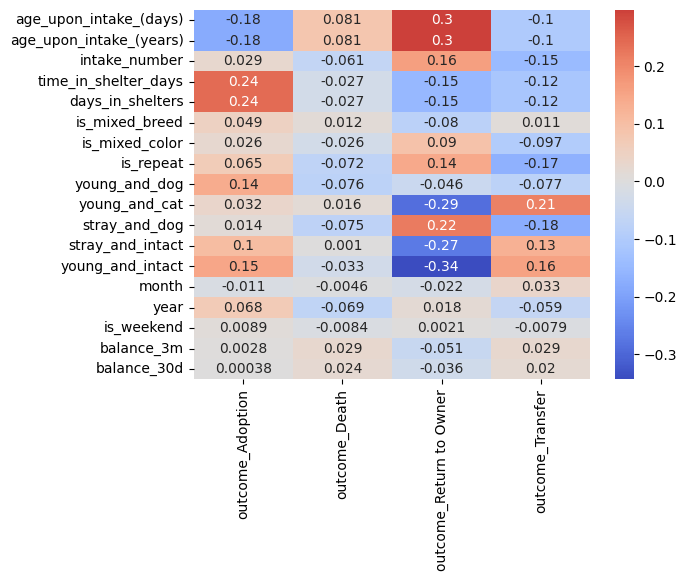

In [21]:
from scipy.stats import pointbiserialr

corr_results = pd.DataFrame(index=num_cols, columns=outcome_ohe.columns)

for outcome in outcome_ohe.columns: 
    for col in num_cols: 
        corr, p = pointbiserialr(outcome_ohe[outcome], df[col])
        corr_results.loc[col, outcome] = corr

corr_results = corr_results.astype(float)
sns.heatmap(corr_results, annot=True, cmap="coolwarm", center=0)

# Correlation analysis highlights potential relationships
# between numerical features and outcome types.
# Weak linear correlations do not necessarily imply
# low predictive value for non-linear models.

# These relationships may also support the interpretation
# of model predictions using SHAP.

In [22]:
corr_results["outcome_Adoption"].sort_values(ascending=False)
#young dogs are adopted more often, older animals less frequently (based on a correlation)
#wild animals are almost never adopted

days_in_shelters           0.241859
time_in_shelter_days       0.241222
young_and_intact           0.149075
young_and_dog              0.138072
stray_and_intact           0.104053
year                       0.067810
is_repeat                  0.064781
is_mixed_breed             0.049203
young_and_cat              0.032133
intake_number              0.028795
is_mixed_color             0.026463
stray_and_dog              0.014157
is_weekend                 0.008888
balance_3m                 0.002811
balance_30d                0.000381
month                     -0.010866
age_upon_intake_(years)   -0.179630
age_upon_intake_(days)    -0.179630
Name: outcome_Adoption, dtype: float64

In [23]:
corr_results["outcome_Transfer"].sort_values(ascending=False)
#young cats are more likely to be transferred (positive correlation with transfer)
#stray dogs, or those that return [to the shelter] more frequently, show a negative correlation—they are less likely to be transferred
#the correlations are moderate


young_and_cat              0.211477
young_and_intact           0.155214
stray_and_intact           0.125172
month                      0.033214
balance_3m                 0.029129
balance_30d                0.020485
is_mixed_breed             0.011120
is_weekend                -0.007864
year                      -0.059339
young_and_dog             -0.076547
is_mixed_color            -0.097243
age_upon_intake_(days)    -0.102004
age_upon_intake_(years)   -0.102004
time_in_shelter_days      -0.117609
days_in_shelters          -0.118321
intake_number             -0.147700
is_repeat                 -0.166743
stray_and_dog             -0.175119
Name: outcome_Transfer, dtype: float64

In [24]:
corr_results["outcome_Death"].sort_values(ascending=False)
#wildlife and others – encounters often end in death for wild animals
#young dogs, strays, and mixed-breed dogs face a lower risk of euthanasia/death
#age does not show a linear correlation with the likelihood of death

age_upon_intake_(days)     0.081487
age_upon_intake_(years)    0.081487
balance_3m                 0.028900
balance_30d                0.023976
young_and_cat              0.016010
is_mixed_breed             0.011992
stray_and_intact           0.001021
month                     -0.004644
is_weekend                -0.008375
is_mixed_color            -0.025813
days_in_shelters          -0.026970
time_in_shelter_days      -0.027073
young_and_intact          -0.033138
intake_number             -0.061226
year                      -0.069418
is_repeat                 -0.071882
stray_and_dog             -0.075096
young_and_dog             -0.076457
Name: outcome_Death, dtype: float64

In [25]:
corr_results["outcome_Return to Owner"].sort_values(ascending=False)
#Older animals have a higher correlation with "Return to Owner" – age influences the likelihood of an animal returning to its owner.
#Animals that end up in the shelter more than once do return to their owners.
#Young cats rarely have an owner.

age_upon_intake_(days)     0.297188
age_upon_intake_(years)    0.297188
stray_and_dog              0.217987
intake_number              0.161520
is_repeat                  0.143571
is_mixed_color             0.090046
year                       0.017530
is_weekend                 0.002085
month                     -0.021746
balance_30d               -0.035613
young_and_dog             -0.046492
balance_3m                -0.050898
is_mixed_breed            -0.079655
time_in_shelter_days      -0.152862
days_in_shelters          -0.152899
stray_and_intact          -0.270969
young_and_cat             -0.286804
young_and_intact          -0.343705
Name: outcome_Return to Owner, dtype: float64

In [26]:
df['intake_type'].value_counts(normalize=True)

intake_type
Stray              0.728378
Owner Surrender    0.204850
Public Assist      0.066771
Name: proportion, dtype: float64

In [27]:
cat_cols = df.select_dtypes(include="object").columns.drop(["outcome_type", "wildlife_and_other",
                         "animal_type_Other", "intact_Unknown", "outcome_subtype",
                         "balance_7m", "time_in_shelter_days", "time_in_shelter",
                         "sex_upon_outcome", "age_upon_intake_(years)", "intake_datetime", "intake_date", 
                         "day_of_week", "month", 'year','is_weekend',"primary_breed_top_Other","intake_number","is_repeat", 
                         'date_of_birth', 'animal_type'], errors="ignore")

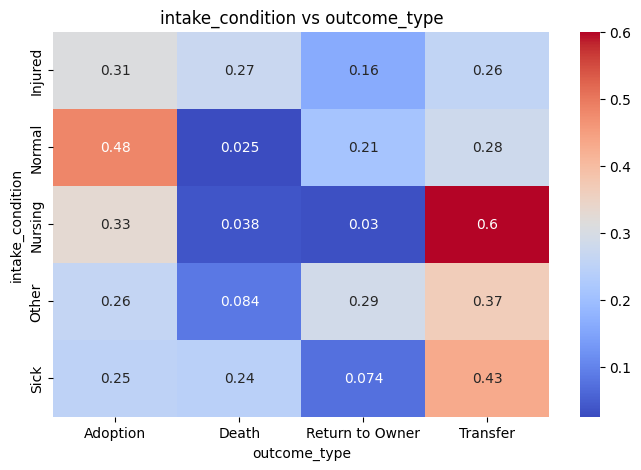

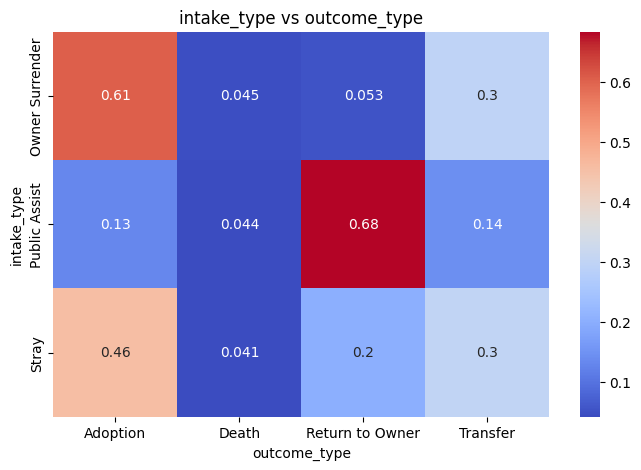

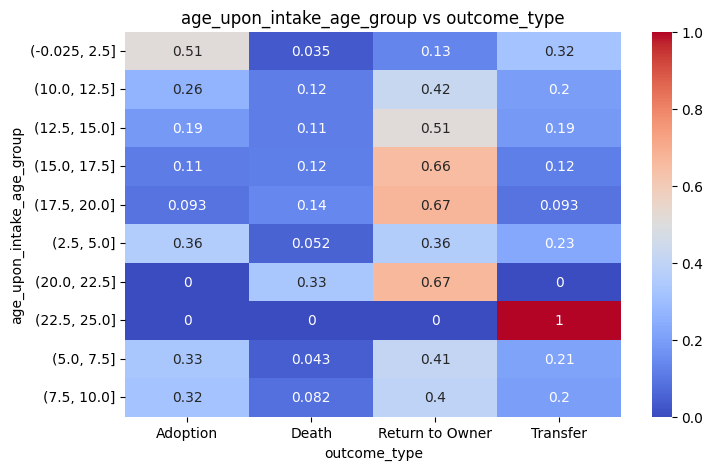

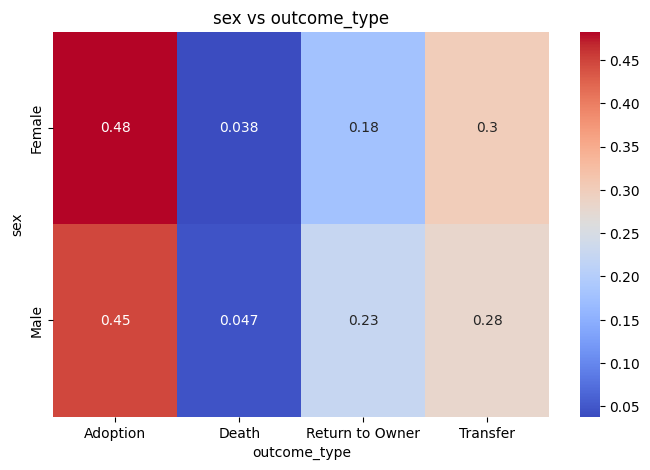

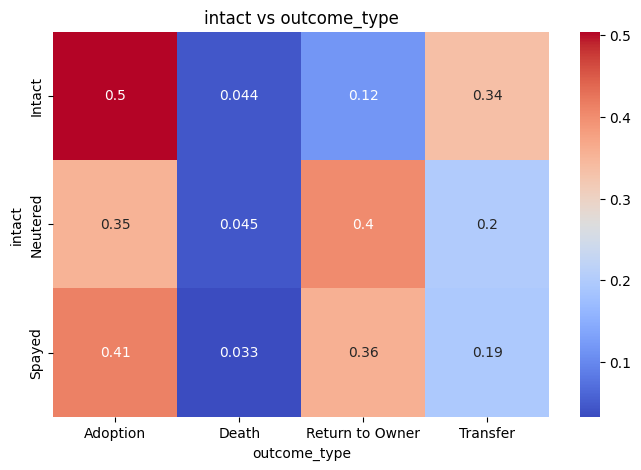

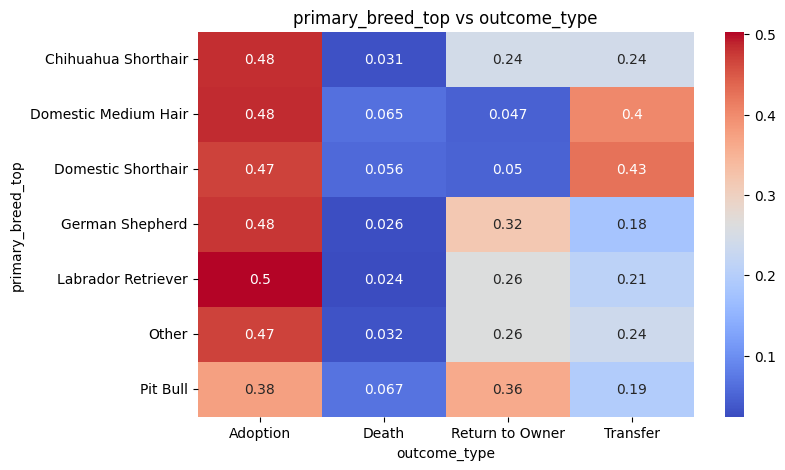

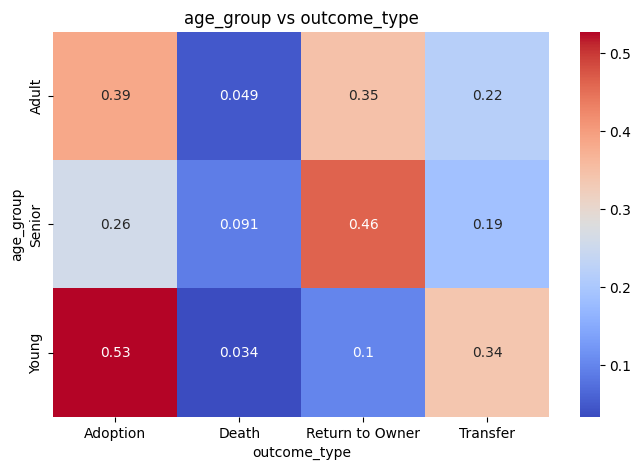

In [28]:
#jaki procent przypadków kończy się danym outcome 
scores = {}
for col in cat_cols:
    crosstab = pd.crosstab(df[col], df["outcome_type"], normalize="index")
    plt.figure(figsize=(8,5))
    sns.heatmap(crosstab, annot=True, cmap="coolwarm")
    plt.title(f"{col} vs outcome_type")
    plt.show()

# Several categorical features appear to be associated
# with different outcome distributions, particularly
# intake-related characteristics and animal demographics.

# Category frequencies should also be considered,
# as percentages based on small sample sizes
# may lead to misleading conclusions.

<Axes: xlabel='month'>

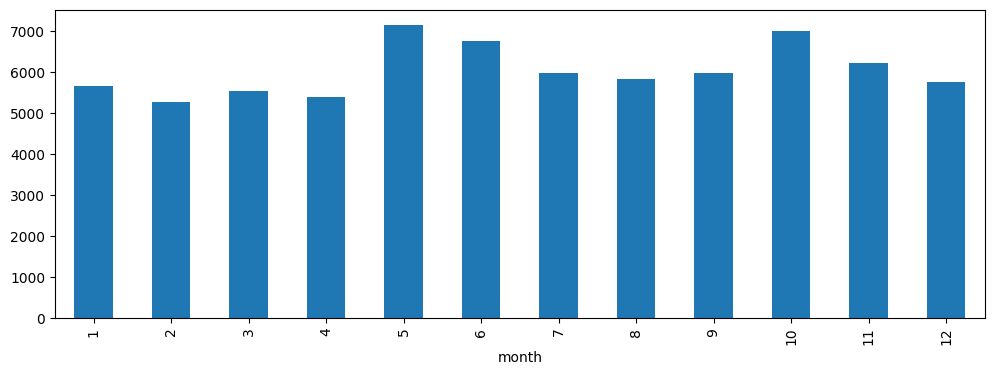

In [29]:
df.groupby("month").size().plot(kind="bar", figsize=(12,4))

# Outcome distributions may vary across months and years,
# potentially reflecting seasonal patterns and changes
# in shelter operations.

# Partial years and differences in the number of recorded
# intakes should be considered when comparing trends.

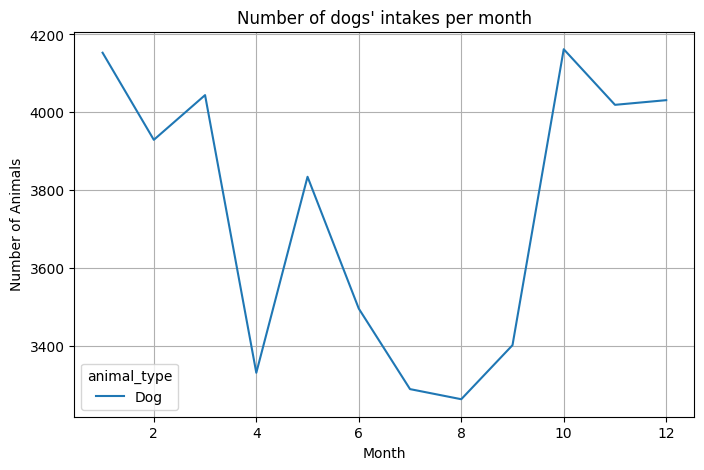

In [30]:

dogs = df[df["animal_type"]=="Dog"]
monthly = pd.crosstab(
    dogs["month"],
    dogs["animal_type"]
)

monthly.plot(kind="line", figsize=(8,5))

plt.title("Number of dogs' intakes per month")
plt.xlabel("Month")
plt.ylabel("Number of Animals")
plt.grid(True)
plt.show()

Text(0, 0.5, 'Count')

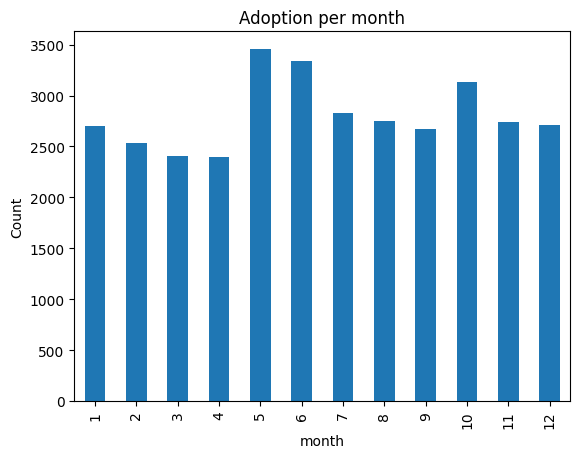

In [31]:
adoptions = df[df["outcome_type"] == "Adoption"]
adoptions.groupby("month").size().plot(kind="bar")

plt.title("Adoption per month")
plt.ylabel("Count")

<Axes: xlabel='year'>

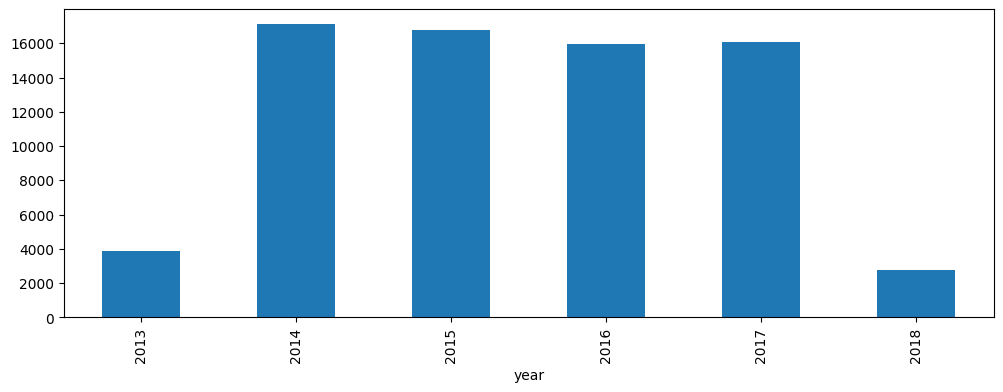

In [32]:
#Number of animals per year
df.groupby("year").size().plot(kind="bar", figsize=(12,4))

In [33]:
df["intake_date"] = pd.to_datetime(df["intake_datetime"]).dt.date
print(f"The oldest date: {df['intake_date'].min()}")
print(f"The newest date: {df['intake_date'].max()}")

The oldest date: 2013-10-01
The newest date: 2018-03-29


<Axes: xlabel='year'>

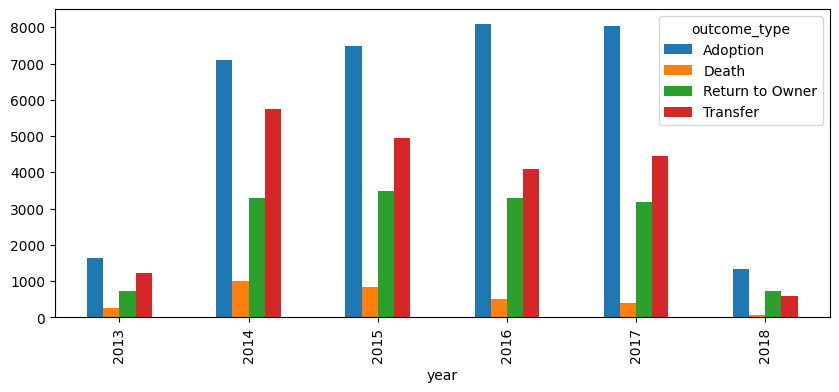

In [34]:
df.groupby(["year", "outcome_type"]).size().unstack(fill_value=0).plot(kind="bar", figsize=(10,4))

<Axes: xlabel='month'>

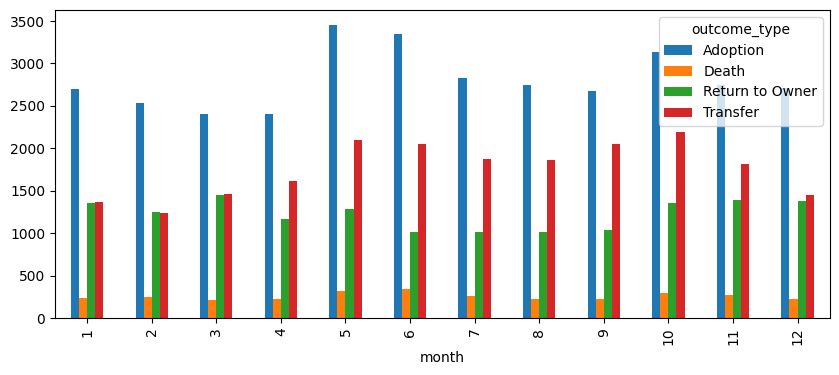

In [35]:
df.groupby(["month", "outcome_type"]).size().unstack(fill_value=0).plot(kind="bar", figsize=(10,4))